# imports


In [ ]:
import numpy as np                      # numpy = library for working with arrays of numbers
from tensorflow.keras.datasets import mnist   # Keras has MNIST built in, so no download needed

# 2. Load the dataset
#    It returns TWO pairs: (training images, training labels) and (test images, test labels)

In [ ]:
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# 3. Look at the shapes (how many images, and what size)
# .shape= (numb of image, rows, colomns)


In [ ]:
print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)
print("X_test:      ", X_test.shape)
print("y_test:      ", y_test.shape)

X_train_full: (60000, 28, 28)
y_train_full: (60000,)
X_test:       (10000, 28, 28)
y_test:       (10000,)


# 4. Look at the numbers inside one image

In [ ]:
print("Smallest pixel value:", X_train_full.min())
print("Largest pixel value: ", X_train_full.max())
print("Label of the first image:", y_train_full[0])

Smallest pixel value: 0
Largest pixel value:  255
Label of the first image: 5


# ba test el labels (print("Label of the first image:", y_train_full[0])) by2ol el label bta3 kol sora which is the image drawn


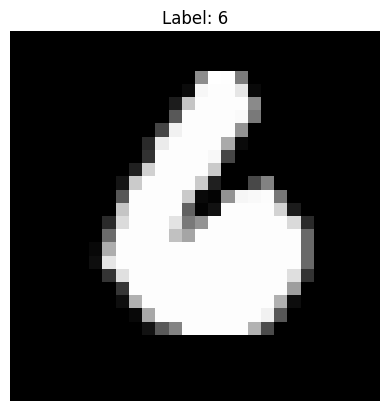

In [ ]:
import matplotlib.pyplot as plt          # matplotlib = library for drawing plots and images

plt.imshow(X_train_full[2005], cmap="gray") # imshow = "image show"; cmap="gray" draws it in black-and-white
plt.title("Label: " + str(y_train_full[2005]))  # put the label above the picture
plt.axis("off")                          # hide the x/y axis numbers
plt.show()                               # display it

# mn el akher by3ml split le 10000 soora (shuffled using train_test_split) 3shan n3ml validation beeha ba3din

In [ ]:
from sklearn.model_selection import train_test_split   # scikit-learn's tool for splitting data

# Split the 60,000 training images into 50,000 train + 10,000 validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,   # the data to split (images and their labels together)
    test_size=10000,              # how many go into the second part (validation)
    random_state=42,              # fixed seed -> same shuffle every time, for everyone
    stratify=y_train_full         # keep the same share of each digit in both parts
)

print("Train:     ", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:      ", X_test.shape, y_test.shape)

Train:      (50000, 28, 28) (50000,)
Validation: (10000, 28, 28) (10000,)
Test:       (10000, 28, 28) (10000,)


# 1. Normalize: divide every pixel by 255 so values go from 0-255 to 0.0-1.0
#    astype("float32") first, because dividing integers would lose the decimals

- .astype("float32") converts whole-number pixels into decimal numbers.

In [ ]:
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

# 2. Flattened version (for Random Forest and MLP): each 28x28 image becomes one row of 784 numbers

- .reshape(...) rearranges the same numbers into a new shape without changing them.

- In reshape(len(X_train), 784), len(X_train) keeps the number of images (50,000). 784 is 28 × 28, so each image becomes one row.

In [ ]:
X_train_flat = X_train.reshape(len(X_train), 784)
X_val_flat   = X_val.reshape(len(X_val), 784)
X_test_flat  = X_test.reshape(len(X_test), 784)

# 3. CNN version: keep the 28x28 grid and add a channel dimension of 1 (grayscale)

- In reshape(len(X_train), 28, 28, 1), the final 1 is the channel dimension: one channel, grayscale.

In [ ]:
X_train_cnn = X_train.reshape(len(X_train), 28, 28, 1)
X_val_cnn   = X_val.reshape(len(X_val), 28, 28, 1)
X_test_cnn  = X_test.reshape(len(X_test), 28, 28, 1)

# 4. Check the results

In [ ]:
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Flat shape: ", X_train_flat.shape)
print("CNN shape:  ", X_train_cnn.shape)

Pixel range: 0.0 to 1.0
Flat shape:  (50000, 784)
CNN shape:   (50000, 28, 28, 1)


# Trees

In [ ]:
import time                                              # to measure how long training takes
from sklearn.ensemble import RandomForestClassifier      # scikit-learn's Random Forest
from sklearn.metrics import accuracy_score               # share of correct predictions

In [ ]:
# 1. Create the forest with experiment A's settings
rf_a = RandomForestClassifier(
    n_estimators=50,     # number of trees that vote
    max_depth=20,        # each tree may ask at most 20 questions in a row
    random_state=42,     # fixed seed so results repeat
    n_jobs=-1            # use all CPU cores to train faster (does not change results)
)

# Train w time

In [ ]:
# 2. Train it, and time it
start = time.time()                  # note the clock before training
rf_a.fit(X_train_flat, y_train)      # builds its trees from the training images and labels.
train_time = time.time() - start     # time after minus time before

In [ ]:
# 3. Predict the validation images and score them
val_pred = rf_a.predict(X_val_flat)              #  gives one guess per image. The forest runs each image through all 50 trees and takes the majority vote.
val_acc = accuracy_score(y_val, val_pred)        # compare guesses with true labels

print("Experiment A: trees=50, max_depth=20")
print("Training time (s):", round(train_time, 1))
print("Validation accuracy:", round(val_acc, 4))

Experiment A: trees=50, max_depth=20
Training time (s): 19.4
Validation accuracy: 0.9631


# Same steps as experiment A so we use function not to repeat ourselves


In [ ]:
def run_rf(name, n_trees, depth):
    model = RandomForestClassifier(
        n_estimators=n_trees,
        max_depth=depth,        # None means "no limit"
        random_state=42,
        n_jobs=-1
    )
    start = time.time()
    model.fit(X_train_flat, y_train)
    train_time = time.time() - start

    val_acc = accuracy_score(y_val, model.predict(X_val_flat))
    print(f"Experiment {name}: trees={n_trees}, max_depth={depth}")
    print("  Training time (s):", round(train_time, 1))
    print("  Validation accuracy:", round(val_acc, 4))
    return model, train_time, val_acc

changing the number of trees

In [ ]:
rf_b, time_b, acc_b = run_rf("B", 100, 20)
rf_c, time_c, acc_c = run_rf("C", 100, None)

Experiment B: trees=100, max_depth=20
  Training time (s): 34.0
  Validation accuracy: 0.9658
Experiment C: trees=100, max_depth=None
  Training time (s): 34.1
  Validation accuracy: 0.9665


In [ ]:
import os        # os lets us ask the computer about files
import joblib    # joblib saves/loads scikit-learn models to/from a file

# Save each experiment to a file, then read how big the file is (in MB)
for name, model in [("A", rf_a), ("B", rf_b), ("C", rf_c)]:
    filename = f"rf_{name}.joblib"
    joblib.dump(model, filename)                      # write the model to disk
    size_mb = os.path.getsize(filename) / (1024 * 1024)   # bytes -> megabytes
    print(f"Experiment {name}: {size_mb:.1f} MB")

Experiment A: 57.5 MB
Experiment B: 114.9 MB
Experiment C: 118.4 MB


In [ ]:
for name, model in [("B", rf_b), ("C", rf_c)]:
    filename = f"rf_{name}_compressed.joblib"
    joblib.dump(model, filename, compress=3)   # compress=3: moderate compression level (0 = none, 9 = max)
    size_mb = os.path.getsize(filename) / (1024 * 1024)
    print(f"Experiment {name} compressed: {size_mb:.1f} MB")


Experiment B compressed: 18.5 MB
Experiment C compressed: 18.9 MB


In [ ]:
# 1. Save the chosen model (compressed) as the final file the app will load
joblib.dump(rf_c, "rf_final.joblib", compress=3)

# 2. Reload it from disk, as the app will do later
rf_loaded = joblib.load("rf_final.joblib")

# 3. Score the reloaded model on the TEST set (first time we touch it)
start = time.time()
test_pred = rf_loaded.predict(X_test_flat)
infer_time = time.time() - start
test_acc = accuracy_score(y_test, test_pred)

print("Test accuracy:", round(test_acc, 4))
print("Predicting 10,000 images took (s):", round(infer_time, 2))
print("Same predictions as the in-memory model?",
      (test_pred == rf_c.predict(X_test_flat)).all())

Test accuracy: 0.9695
Predicting 10,000 images took (s): 0.63
Same predictions as the in-memory model? True


In [ ]:
from google.colab import files
files.download("rf_final.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>